# Έλεγχοι (επαναλαμβανόμενοι)
Τρέχουν **μετά από κάθε αλλαγή** στο `line_items.py`, `piotroski.py` ή στο ingest.
Μόνο ανάγνωση — κανένα κελί εδώ δεν γράφει στη βάση.

Σειρά χρήσης όταν αλλάζεις κώδικα:
1. **Πριν** την αλλαγή: κελί «Baseline» (μία φορά).
2. **Μετά** την αλλαγή: restart kernel → κελί «Regression». Κάθε γραμμή που αλλάζει πρέπει να την εξηγούμε.
3. Κελί «Κάλυψη» για το ποσοστό N/A σε όλο το universe.

In [1]:
# ── SETUP (dev notebooks ζουν στο dev/, αλλά δουλεύουν από τη ρίζα του repo) ──
import os, sys
if os.path.basename(os.getcwd()) == "dev":
    os.chdir("..")                      # ώστε να βρίσκει data/ και quality_scores/
sys.path.insert(0, os.getcwd())

import warnings; warnings.filterwarnings("ignore")
import pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import text
from db import get_engine
eng = get_engine()
print("Φάκελος εργασίας:", os.getcwd())
from quality_scores import diagnostics as dg


Φάκελος εργασίας: C:\Users\georg\Google Drive\Python Finance\single_asset_analyzer


## Baseline — τρέξε ΠΡΙΝ αλλάξεις κώδικα

In [ ]:
dg.save_baseline(eng)   # γράφει data/piotroski_baseline.csv (MSFT, AAPL, PPL, ULTA, LHX)


## Regression — τρέξε ΜΕΤΑ την αλλαγή (με restart kernel πρώτα)

In [ ]:
changes = dg.compare_to_baseline(eng)
print("Καμία αλλαγή ✓" if changes.empty else changes.to_string())


## Κάλυψη — % N/A ανά κριτήριο σε όλο το universe (~5 λεπτά)

In [ ]:
cov = dg.coverage_report(eng)          # σώζει και data/piotroski_coverage.csv
print(f"{len(cov)} εταιρείες με score\n")
print(dg.na_rates(cov).to_string())


In [ ]:
# Ανά sector: είναι το N/A "λογικό" (τράπεζες, REITs) ή κενό δεδομένων;
print(dg.na_by_sector(cov).to_string())


## Ποιότητα δεδομένων (κενά χρονιών ανά έτος / sector)

── Ποιότητα ετήσιων δεδομένων: 684 εταιρείες ──
   με κενό κάπου στο ιστορικό                         81  (11.8%)
   με κενό στα τελευταία 3 χρόνια τους                 8  ( 1.2%)
   με κενό στα τελευταία 5 χρόνια τους                19  ( 2.8%)
   με κενό στα τελευταία 10 χρόνια τους               54  ( 7.9%)
   χειροκίνητες εξαιρέσεις (ticker recycling κ.λπ.)    2  ( 0.3%)
   Χρονιές που λείπουν συνολικά: 115


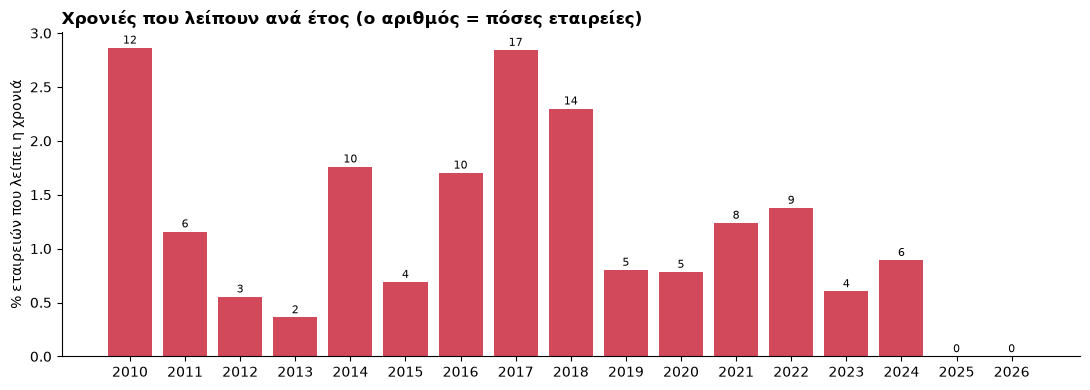

🔄 Sector + Market Cap lookup for 684 tickers...
  ✅ 25/684
  ✅ 50/684
  ✅ 75/684
  ✅ 100/684
  ✅ 125/684
  ✅ 150/684
  ✅ 175/684
  ✅ 200/684
  ✅ 225/684
  ✅ 250/684
  ✅ 275/684
  ✅ 300/684
  ✅ 325/684
  ✅ 350/684
  ✅ 375/684
  ✅ 400/684
  ✅ 425/684
  ✅ 450/684
  ✅ 475/684
  ✅ 500/684
  ✅ 525/684
  ✅ 550/684
  ✅ 575/684
  ✅ 600/684
  ✅ 625/684
  ✅ 650/684
  ✅ 675/684
                        companies  with_gap  pct_with_gap
sector                                                   
Real Estate                    41         8     19.512195
Basic Materials                27         5     18.518519
Utilities                      32         5     15.625000
Energy                         38         5     13.157895
Consumer Defensive             39         5     12.820513
Financial Services             95        12     12.631579
Technology                    103        12     11.650485
Industrials                   107        12     11.214953
Healthcare                     78         7      8.

In [ ]:
import matplotlib.pyplot as plt
from data_quality import (data_quality_report, summarize, gaps_by_year,
                          plot_gaps_by_year, gaps_by_sector, excluded_tickers)
from sector_lookup import get_sectors

report = data_quality_report(eng)
summarize(report)

plot_gaps_by_year(gaps_by_year(report))
plt.show()

# Την πρώτη φορά αργεί λίγα λεπτά (ρωτάει το yfinance για κάθε εταιρεία),
# μετά κρατάει cache 30 ημερών στο data/.
print(gaps_by_sector(report, get_sectors(list(report.index))).head(12).to_string())

In [ ]:
from sqlalchemy import text
universe = pd.read_sql(text(
    "SELECT DISTINCT c.ticker FROM companies c JOIN fundamentals f ON f.ticker = c.ticker"
), eng)["ticker"]
no_annual = sorted(set(universe) - set(report.index))
print(f"{len(no_annual)} εταιρείες χωρίς κανένα ετήσιο 10-K:")
print(no_annual)

92 εταιρείες χωρίς κανένα ετήσιο 10-K:
['ABC', 'ABMD', 'AL', 'ANSS', 'APC', 'ARC', 'ARNC', 'ASC', 'ATVI', 'BHGE', 'BIG', 'BK', 'BLL', 'CDAY', 'CHA', 'CHK', 'CMA', 'CTL', 'CTLT', 'CTRA', 'CTXS', 'DFS', 'DISH', 'DNB', 'DO', 'DRE', 'EA', 'EC', 'EQR', 'FB', 'FBHS', 'FL', 'FLT', 'FRO', 'GPS', 'HBI', 'HCP', 'HES', 'HI', 'HOLX', 'HONA', 'IAC', 'IGT', 'IPG', 'JNPR', 'JWN', 'K', 'LSI', 'MI', 'MMC', 'MRO', 'MTL', 'NCR', 'NLOK', 'NLSN', 'ODP', 'PCH', 'PDCO', 'PEAK', 'PKI', 'POM', 'PX', 'PXD', 'RAD', 'RE', 'RYI', 'SATS', 'SB', 'SE', 'SEE', 'SIVB', 'SNT', 'SNV', 'SOV', 'SRCL', 'SWN', 'TEN', 'TGNA', 'TMK', 'TUP', 'TWTR', 'TWX', 'UCL', 'UK', 'UPC', 'WAI', 'WB', 'WBA', 'WLTW', 'WRK', 'X', 'XOM']
